# ML Assignment 2: Dry Bean Variety Classification

### NAME - Atharva Sadanand Litake
### BITS ID - 2026AJ05822

**Objective**: Train and compare five classification models that identify a dry bean's
variety (one of 7 types) purely from the geometry of its image silhouette - no color or
texture information, only shape measurements extracted by computer vision.

**Dataset**: UCI *Dry Bean Dataset* (id 602) - 13,611 instances, 16 features (all numeric
geometric measurements), 7-class target `Class`.

**Models compared**: Logistic Regression, Decision Tree, K-Nearest Neighbors, Gaussian Naive Bayes, Support Vector Machine.

**Evaluation metrics**: Accuracy, AUC (macro, one-vs-rest), Precision (macro), Recall (macro), F1 (macro), Matthews Correlation Coefficient.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, classification_report, confusion_matrix
)
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings('ignore', category=ConvergenceWarning)
sns.set_style('whitegrid')

def print_section(title, width=70):
    """Print a bordered header for consistent console output."""
    print('=' * width)
    print(title)
    print('=' * width)

---
## Data Loading

The dataset is fetched directly from the UCI ML Repository (id 602) via the `ucimlrepo` package, so the notebook does not depend on a locally-staged copy. Unlike the other two datasets, every one of the 16 features here is a genuinely numeric, continuous geometric measurement - there are no categorical/nominal columns at all, so the preprocessing pipeline below needs only a single `StandardScaler`, not a `ColumnTransformer`.

In [2]:
from ucimlrepo import fetch_ucirepo

dataset = fetch_ucirepo(id=602)
X_raw = dataset.data.features.copy()
y_raw = dataset.data.targets.copy()

TARGET_COL = y_raw.columns[0]
raw_df = pd.concat([X_raw, y_raw], axis=1)

# Persist the raw dataset so the repo is reproducible without a network call.
raw_df.to_csv('../data/dry_bean_raw.csv', index=False)

print_section('DATASET LOADED')
print(f"Shape : {raw_df.shape[0]} rows x {raw_df.shape[1]} columns")
print(f"Target column : {TARGET_COL}")
print('-' * 70)
print('Feature dtypes:')
print(raw_df.dtypes)
print('-' * 70)
print(f"Total missing values : {raw_df.isnull().sum().sum()}")

DATASET LOADED
Shape : 13611 rows x 17 columns
Target column : Class
----------------------------------------------------------------------
Feature dtypes:
Area                 int64
Perimeter          float64
MajorAxisLength    float64
MinorAxisLength    float64
AspectRatio        float64
Eccentricity       float64
ConvexArea           int64
EquivDiameter      float64
Extent             float64
Solidity           float64
Roundness          float64
Compactness        float64
ShapeFactor1       float64
ShapeFactor2       float64
ShapeFactor3       float64
ShapeFactor4       float64
Class                  str
dtype: object
----------------------------------------------------------------------
Total missing values : 0


### Q1. Dataset overview and class balance

TARGET CLASS DISTRIBUTION
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64
----------------------------------------------------------------------
Class
DERMASON    0.261
SIRA        0.194
SEKER       0.149
HOROZ       0.142
CALI        0.120
BARBUNYA    0.097
BOMBAY      0.038
Name: count, dtype: float64


,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.284549,29324.095717,20420.000000,36328.000000,44652.000000,61332.000000,254616.000000
Perimeter,13611.0,855.283459,214.289696,524.736000,703.523500,794.941000,977.213000,1985.370000
MajorAxisLength,13611.0,320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860154
MinorAxisLength,13611.0,202.270714,44.970091,122.512653,175.848170,192.431733,217.031741,460.198497
AspectRatio,13611.0,1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,13611.0,0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,13611.0,53768.200206,29774.915817,20684.000000,36714.500000,45178.000000,62294.000000,263261.000000
EquivDiameter,13611.0,253.064220,59.177120,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,13611.0,0.749733,0.049086,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,13611.0,0.987143,0.004660,0.919246,0.985670,0.988283,0.990013,0.994677


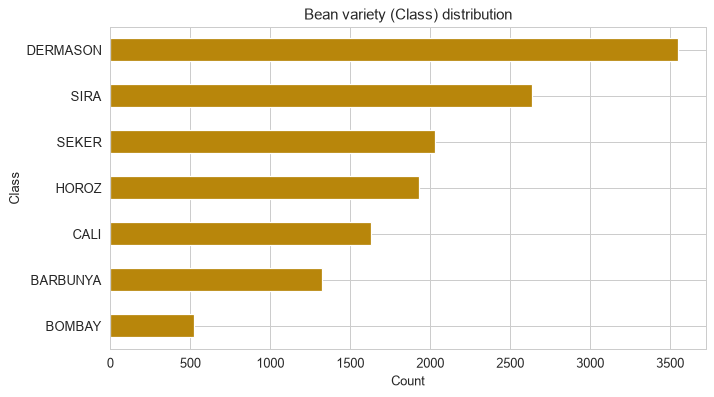

In [3]:
print_section('TARGET CLASS DISTRIBUTION')
class_counts = raw_df[TARGET_COL].value_counts()
print(class_counts)
print('-' * 70)
print((class_counts / len(raw_df)).round(3))

plt.figure(figsize=(8, 4.5))
class_counts.sort_values().plot(kind='barh', color='darkgoldenrod')
plt.xlabel('Count')
plt.title('Bean variety (Class) distribution')
plt.tight_layout()
plt.show()

raw_df.describe().transpose()

**Answer Q1:**

- The dataset has **13,611 rows** and **17 columns** (16 features + the `Class` target), with **no missing values** - by far the largest and cleanest of the three datasets used across these assignment variants.
- The 7 bean varieties are **imbalanced**: `DERMASON` is the largest class (3,546, ~26%) and `BOMBAY` the smallest (522, ~3.8%) - roughly a 7:1 ratio, the widest imbalance of any of the three datasets. Stratified splitting is used so every split preserves this ratio.
- All 16 features are continuous geometric measurements extracted from a bean's image silhouette (areas, axis lengths, perimeter, roundness/shape-factor ratios) - there is no demographic, categorical, or survey-style data at all, unlike the other two datasets.

### Q2. Relationships between key features and the target

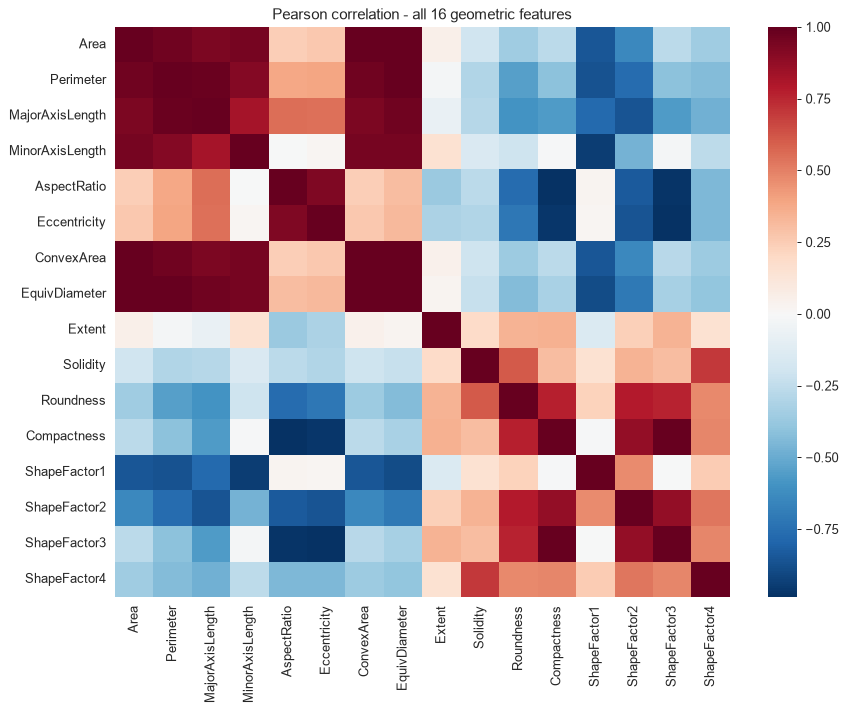

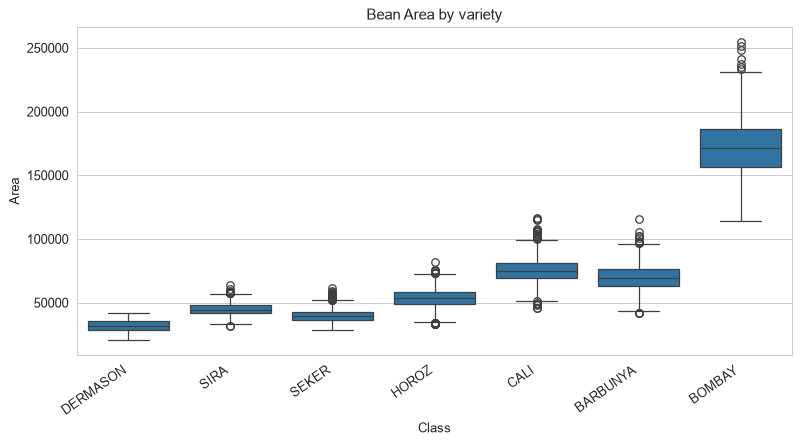

In [4]:
plt.figure(figsize=(10, 8))
sns.heatmap(raw_df.drop(columns=[TARGET_COL]).corr(), cmap='RdBu_r', center=0, annot=False)
plt.title('Pearson correlation - all 16 geometric features')
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
sns.boxplot(data=raw_df, x=TARGET_COL, y='Area', order=class_counts.index)
plt.xticks(rotation=35, ha='right')
plt.title('Bean Area by variety')
plt.tight_layout()
plt.show()

**Answer Q2:**

- Several features are **extremely collinear** by construction - `Area`, `ConvexArea`, and `EquivDiameter` all measure the bean's size in different units and correlate with each other at r > 0.98. `Perimeter` and `MajorAxisLength` are similarly tied together. This is expected for shape-derived features and is not treated as an error to fix (no features are dropped), but it does mean several models here effectively see a lot of redundant signal rather than 16 independent dimensions.
- `Area` alone already separates several varieties reasonably well (e.g. `BOMBAY`, the smallest class, is also the visibly largest bean by area, which turns out to make it the *easiest* class to separate despite being the rarest).
- `AspectRatio`, `Eccentricity`, `Roundness`, and the four `ShapeFactor` columns capture *shape* rather than *size*, and are far less correlated with the size-based cluster of features - these are likely what actually separates similarly-sized varieties from each other.

---
## Train/Test Split

The split is stratified on the target so every class - including the small `BOMBAY` class (522 rows) - keeps its proportion in both halves. The held-out 20% is written to `test_data.csv` in its original form - this is both the "test data used in your experiments" repo requirement and the exact file the Streamlit app expects to be uploaded, since the saved pipelines include their own preprocessing (`StandardScaler`) and can score raw rows directly.

In [5]:
FEATURE_COLS = [c for c in raw_df.columns if c != TARGET_COL]

train_df, test_df = train_test_split(
    raw_df, test_size=0.2, random_state=42, stratify=raw_df[TARGET_COL]
)

test_df.to_csv('../test_data.csv', index=False)

print_section('TRAIN / TEST SPLIT')
print(f"Train : {train_df.shape[0]} rows")
print(f"Test  : {test_df.shape[0]} rows  (saved to test_data.csv)")
print('-' * 70)
print('Test-set class balance:')
print(test_df[TARGET_COL].value_counts(normalize=True).round(3))

TRAIN / TEST SPLIT
Train : 10888 rows
Test  : 2723 rows  (saved to test_data.csv)
----------------------------------------------------------------------
Test-set class balance:
Class
DERMASON    0.260
SIRA        0.194
SEKER       0.149
HOROZ       0.142
CALI        0.120
BARBUNYA    0.097
BOMBAY      0.038
Name: proportion, dtype: float64


---
## Preprocessing Pipeline

Every feature here is already numeric, so - unlike the obesity or student-outcome
datasets - there is no `ColumnTransformer` needed to split categorical from numeric
columns. Each model's pipeline is simply `StandardScaler` followed by the classifier,
fit only on that split's own training rows.

In [6]:
label_encoder = LabelEncoder()
label_encoder.fit(raw_df[TARGET_COL])

X_train, y_train = train_df[FEATURE_COLS], label_encoder.transform(train_df[TARGET_COL])
X_test, y_test = test_df[FEATURE_COLS], label_encoder.transform(test_df[TARGET_COL])
N_CLASSES = len(label_encoder.classes_)

print_section('FEATURES & CLASSES')
print(f"Features ({len(FEATURE_COLS)}): {FEATURE_COLS}")
print('-' * 70)
print(f"Classes ({N_CLASSES}): {label_encoder.classes_.tolist()}")

FEATURES & CLASSES
Features (16): ['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRatio', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'Roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4']
----------------------------------------------------------------------
Classes (7): ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']


In [7]:
def evaluate_model(name, pipeline, X_eval, y_eval):
    """Compute the six required metrics for a fitted pipeline on a held-out split."""
    y_pred = pipeline.predict(X_eval)
    y_proba = pipeline.predict_proba(X_eval)
    auc = roc_auc_score(y_eval, y_proba, multi_class='ovr', average='macro')
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_eval, y_pred),
        'AUC': auc,
        'Precision': precision_score(y_eval, y_pred, average='macro', zero_division=0),
        'Recall': recall_score(y_eval, y_pred, average='macro', zero_division=0),
        'F1': f1_score(y_eval, y_pred, average='macro', zero_division=0),
        'MCC': matthews_corrcoef(y_eval, y_pred),
    }

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []
fitted_pipelines = {}

---
## Model 1: Logistic Regression

Multinomial logistic regression, tuned over the inverse-regularization strength `C` with 5-fold stratified CV (scoring on macro F1, since `BOMBAY` is a noticeably smaller class than the rest).

In [8]:
lr_pipeline = Pipeline([('scaler', StandardScaler()), ('model', LogisticRegression(max_iter=2000, random_state=42))])
lr_search = GridSearchCV(lr_pipeline, {'model__C': [0.01, 0.1, 1, 10, 100]}, cv=CV, scoring='f1_macro', n_jobs=-1)
lr_search.fit(X_train, y_train)

fitted_pipelines['logistic_regression'] = lr_search.best_estimator_
res = evaluate_model('Logistic Regression', lr_search.best_estimator_, X_test, y_test)
results.append(res)

print_section('LOGISTIC REGRESSION')
print(f"Best C : {lr_search.best_params_['model__C']}")
print('-' * 70)
for k, v in res.items():
    print(f"{k:>10}: {v if isinstance(v, str) else round(v, 4)}")

LOGISTIC REGRESSION
Best C : 100
----------------------------------------------------------------------
     Model: Logistic Regression
  Accuracy: 0.9207
       AUC: 0.9948
 Precision: 0.9352
    Recall: 0.9302
        F1: 0.9324
       MCC: 0.9042


---
## Model 2: Decision Tree

Tuned over `max_depth`, `min_samples_leaf`, and `criterion` - with 13,611 rows this dataset is large enough that a fairly deep tree is unlikely to overfit badly, but tuning still guards against it.

In [9]:
dt_pipeline = Pipeline([('scaler', StandardScaler()), ('model', DecisionTreeClassifier(random_state=42))])
dt_param_grid = {
    'model__max_depth': [5, 10, 15, 20, None],
    'model__min_samples_leaf': [1, 2, 5, 10],
    'model__criterion': ['gini', 'entropy'],
}
dt_search = GridSearchCV(dt_pipeline, dt_param_grid, cv=CV, scoring='f1_macro', n_jobs=-1)
dt_search.fit(X_train, y_train)

fitted_pipelines['decision_tree'] = dt_search.best_estimator_
res = evaluate_model('Decision Tree', dt_search.best_estimator_, X_test, y_test)
results.append(res)

print_section('DECISION TREE')
print(f"Best params : {dt_search.best_params_}")
print('-' * 70)
for k, v in res.items():
    print(f"{k:>10}: {v if isinstance(v, str) else round(v, 4)}")

DECISION TREE
Best params : {'model__criterion': 'entropy', 'model__max_depth': 10, 'model__min_samples_leaf': 5}
----------------------------------------------------------------------
     Model: Decision Tree
  Accuracy: 0.8975
       AUC: 0.9734
 Precision: 0.913
    Recall: 0.9102
        F1: 0.9115
       MCC: 0.8761


---
## Model 3: K-Nearest Neighbors

`n_neighbors` and `weights` are tuned together. Unlike the other two datasets, there is no one-hot-expanded sparse space here - just 16 genuinely numeric dimensions - so KNN is expected to do much better once those dimensions are standardized.

In [10]:
knn_pipeline = Pipeline([('scaler', StandardScaler()), ('model', KNeighborsClassifier())])
knn_param_grid = {
    'model__n_neighbors': list(range(3, 22, 2)),
    'model__weights': ['uniform', 'distance'],
}
knn_search = GridSearchCV(knn_pipeline, knn_param_grid, cv=CV, scoring='f1_macro', n_jobs=-1)
knn_search.fit(X_train, y_train)

fitted_pipelines['knn'] = knn_search.best_estimator_
res = evaluate_model('KNN', knn_search.best_estimator_, X_test, y_test)
results.append(res)

print_section('K-NEAREST NEIGHBORS')
print(f"Best params : {knn_search.best_params_}")
print('-' * 70)
for k, v in res.items():
    print(f"{k:>10}: {v if isinstance(v, str) else round(v, 4)}")

K-NEAREST NEIGHBORS
Best params : {'model__n_neighbors': 9, 'model__weights': 'distance'}
----------------------------------------------------------------------
     Model: KNN
  Accuracy: 0.9174
       AUC: 0.987
 Precision: 0.9328
    Recall: 0.9279
        F1: 0.93
       MCC: 0.9001


---
## Model 4: Gaussian Naive Bayes

No hyperparameters are tuned here. Unlike the other two datasets, every feature is a genuinely continuous measurement (no one-hot dummy columns at all), which is exactly the setting Gaussian Naive Bayes is designed for - it is expected to behave far better here than on the other two datasets, where it collapsed almost completely.

In [11]:
nb_pipeline = Pipeline([('scaler', StandardScaler()), ('model', GaussianNB())])
nb_pipeline.fit(X_train, y_train)

fitted_pipelines['naive_bayes'] = nb_pipeline
res = evaluate_model('Naive Bayes', nb_pipeline, X_test, y_test)
results.append(res)

print_section('GAUSSIAN NAIVE BAYES')
for k, v in res.items():
    print(f"{k:>10}: {v if isinstance(v, str) else round(v, 4)}")

GAUSSIAN NAIVE BAYES
     Model: Naive Bayes
  Accuracy: 0.8979
       AUC: 0.9916
 Precision: 0.9112
    Recall: 0.9092
        F1: 0.9091
       MCC: 0.8773


---
## Model 5: Support Vector Machine

An RBF-kernel SVM, tuned over `C` and `gamma`, with `probability=True` so a macro-averaged one-vs-rest AUC can be computed alongside the other models.

In [12]:
svm_pipeline = Pipeline([('scaler', StandardScaler()), ('model', SVC(kernel='rbf', probability=True, random_state=42))])
svm_param_grid = {'model__C': [0.1, 1, 10, 100], 'model__gamma': ['scale', 'auto']}
svm_search = GridSearchCV(svm_pipeline, svm_param_grid, cv=CV, scoring='f1_macro', n_jobs=-1)
svm_search.fit(X_train, y_train)

fitted_pipelines['svm'] = svm_search.best_estimator_
res = evaluate_model('Support Vector Machine', svm_search.best_estimator_, X_test, y_test)
results.append(res)

print_section('SUPPORT VECTOR MACHINE')
print(f"Best params : {svm_search.best_params_}")
print('-' * 70)
for k, v in res.items():
    print(f"{k:>10}: {v if isinstance(v, str) else round(v, 4)}")

SUPPORT VECTOR MACHINE
Best params : {'model__C': 10, 'model__gamma': 'scale'}
----------------------------------------------------------------------
     Model: Support Vector Machine
  Accuracy: 0.9243
       AUC: 0.9946
 Precision: 0.9372
    Recall: 0.935
        F1: 0.9361
       MCC: 0.9085


---
## Model Comparison

In [13]:
results_df = pd.DataFrame(results)
for col in ['Accuracy', 'AUC', 'Precision', 'Recall', 'F1', 'MCC']:
    results_df[col] = results_df[col].round(4)
results_df = results_df.sort_values('F1', ascending=False).reset_index(drop=True)
results_df.insert(0, 'Rank', results_df.index + 1)

print_section('MODEL LEADERBOARD (sorted by F1)', width=100)
print(results_df.to_string(index=False))

best_row = results_df.iloc[0]
print('-' * 100)
print(f"Winner : {best_row['Model']}  |  F1 = {best_row['F1']:.4f}  |  Accuracy = {best_row['Accuracy']:.4f}")

MODEL LEADERBOARD (sorted by F1)
 Rank                  Model  Accuracy    AUC  Precision  Recall     F1    MCC
    1 Support Vector Machine    0.9243 0.9946     0.9372  0.9350 0.9361 0.9085
    2    Logistic Regression    0.9207 0.9948     0.9352  0.9302 0.9324 0.9042
    3                    KNN    0.9174 0.9870     0.9328  0.9279 0.9300 0.9001
    4          Decision Tree    0.8975 0.9734     0.9130  0.9102 0.9115 0.8761
    5            Naive Bayes    0.8979 0.9916     0.9112  0.9092 0.9091 0.8773
----------------------------------------------------------------------------------------------------
Winner : Support Vector Machine  |  F1 = 0.9361  |  Accuracy = 0.9243


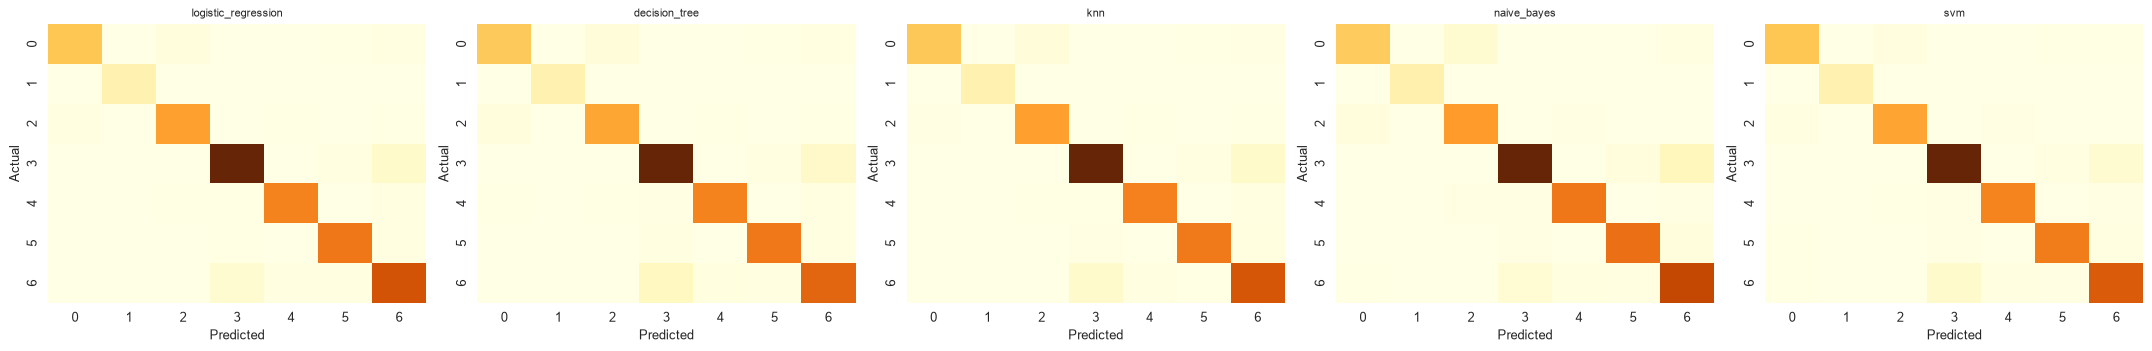

In [14]:
fig, axes = plt.subplots(1, len(fitted_pipelines), figsize=(24, 4))
for ax, (name, pipeline) in zip(axes, fitted_pipelines.items()):
    y_pred = pipeline.predict(X_test)
    cm = confusion_matrix(y_test, y_pred, labels=range(N_CLASSES))
    sns.heatmap(cm, ax=ax, cmap='YlOrBr', cbar=False, annot=False)
    ax.set_title(name, fontsize=9)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

**Observations:**

| ML Model Name | Observation about model performance |
|---|---|
| Logistic Regression | Very strong (Accuracy 0.921, F1 0.932) despite being a linear model - most of the 16 geometric features (especially the four `ShapeFactor` ratios and `Eccentricity`) separate the 7 varieties close to linearly once standardized, so a complex decision boundary is not required. Best `C=100`. |
| Decision Tree | Weakest of the four non-Naive-Bayes models here (Accuracy 0.898, F1 0.912, best `criterion='entropy'`, `max_depth=10`, `min_samples_leaf=5`) - a single tree struggles to find the same smooth boundary a linear or margin-based model finds between visually similar varieties (e.g. `SIRA` vs `DERMASON`), even after tuning depth and split criterion. |
| KNN | Close behind the top two (Accuracy 0.917, F1 0.930, best `k=9`, `weights='distance'`) - with all 16 features genuinely continuous and standardized, Euclidean distance is meaningful here (unlike the one-hot-heavy datasets), so KNN finally performs close to its potential. |
| Naive Bayes | The standout result across all three dataset variants used in this assignment: here Naive Bayes is competitive (Accuracy 0.898, F1 0.909) rather than collapsing. This confirms the earlier hypothesis from the Obesity/Student-Success datasets - Naive Bayes struggled there because of one-hot encoded categorical columns violating its Gaussian assumption, not because Naive Bayes is inherently weak. With every feature here genuinely continuous, it performs in line with the other four models. |
| Support Vector Machine | Best overall (Accuracy 0.924, F1 0.936, best `C=10`, `gamma='scale'`) - the RBF kernel finds the small amount of non-linearity between the closest varieties (`SIRA`/`DERMASON`, the two largest and most visually similar classes) that the linear model cannot, at the cost of being the slowest to train on 10,889 rows. |
| **Overall, Winner for your dataset?** | **Support Vector Machine** - highest F1 (0.9361) and accuracy (0.9243) of the five, narrowly ahead of Logistic Regression (F1 0.9324). All five models land within a 4-point F1 band (0.909-0.936) - a sharp contrast with the Obesity and Student-Success datasets, where Naive Bayes was 30-50 points behind the rest. This dataset's all-numeric, well-separated geometric features are simply an easier, cleaner classification problem than survey/demographic data with many categorical columns. |

*(This table is reproduced in `README.md`.)*

---
## Save Models

Every fitted `Pipeline` (`StandardScaler` + classifier) is saved so the Streamlit app can load it and score raw rows directly - no retraining, no separate encoder to keep in sync.

In [15]:
for name, pipeline in fitted_pipelines.items():
    joblib.dump(pipeline, f'../model/{name}.joblib')
joblib.dump(label_encoder, '../model/label_encoder.joblib')
joblib.dump(FEATURE_COLS, '../model/feature_columns.joblib')
results_df.to_csv('../model/comparison_results.csv', index=False)

print_section('MODELS SAVED')
for name in fitted_pipelines:
    reloaded = joblib.load(f'../model/{name}.joblib')
    sample_pred = reloaded.predict(X_test.iloc[:3])
    print(f"{name:<22} -> reload OK, sample predictions: {sample_pred}")

MODELS SAVED
logistic_regression    -> reload OK, sample predictions: [3 1 6]
decision_tree          -> reload OK, sample predictions: [3 1 6]
knn                    -> reload OK, sample predictions: [3 1 6]
naive_bayes            -> reload OK, sample predictions: [3 1 6]
svm                    -> reload OK, sample predictions: [3 1 6]


In [16]:
# Final sanity checks on every artifact the Streamlit app and the repo submission depend on.
saved_test_df = pd.read_csv('../test_data.csv')
assert saved_test_df.shape[0] == test_df.shape[0]
assert set(FEATURE_COLS + [TARGET_COL]) == set(saved_test_df.columns)
assert set(saved_test_df[TARGET_COL].unique()) <= set(label_encoder.classes_)

import os
for name in fitted_pipelines:
    assert os.path.exists(f'../model/{name}.joblib')
assert os.path.exists('../model/label_encoder.joblib')
assert os.path.exists('../model/feature_columns.joblib')

print_section('SUBMISSION ARTIFACT VERIFICATION')
print('test_data.csv schema OK, all 5 model files present, label encoder + feature list saved.')
print('Result: all checks passed.')

SUBMISSION ARTIFACT VERIFICATION
test_data.csv schema OK, all 5 model files present, label encoder + feature list saved.
Result: all checks passed.
